In [2]:
%pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, joblib, json, shap

model = joblib.load("../models/fraud_xgb.joblib")
features = json.load(open("../models/features.json"))
threshold = json.load(open("../models/threshold.json"))["threshold"]

df = pd.read_pickle("../data/features.pkl")
test = df[df["split"] == "test"]
X_test = test[features]
pred = pd.read_pickle("../data/test_predictions.pkl")   # same row index as test

In [2]:
fraud_rows = X_test[test["is_fraud"] == 1].sample(1000, random_state=1)
genuine_rows = X_test[test["is_fraud"] == 0].sample(3000, random_state=1)
sample = pd.concat([fraud_rows, genuine_rows])

explainer = shap.TreeExplainer(model)
sv = explainer(sample)

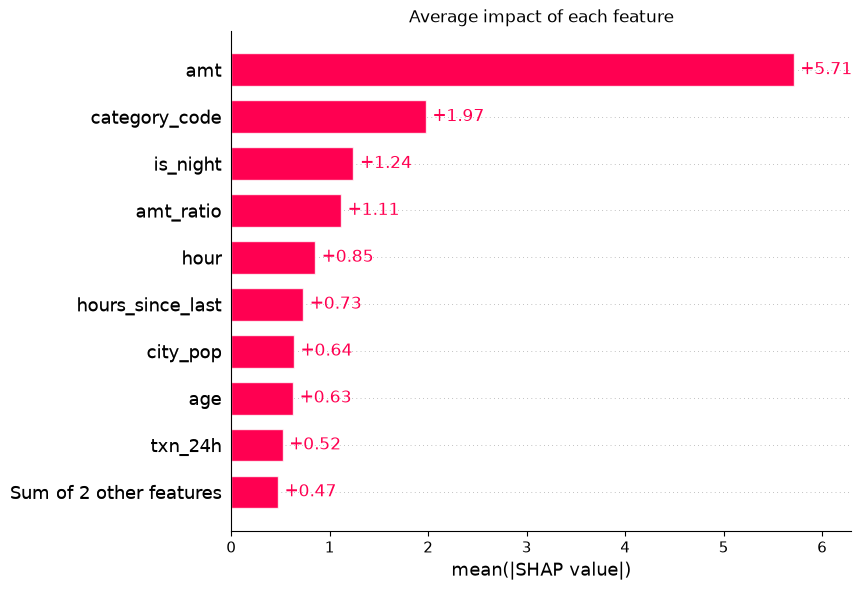

In [3]:
shap.plots.bar(sv, show=False)
plt.title("Average impact of each feature")
plt.savefig("../images/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

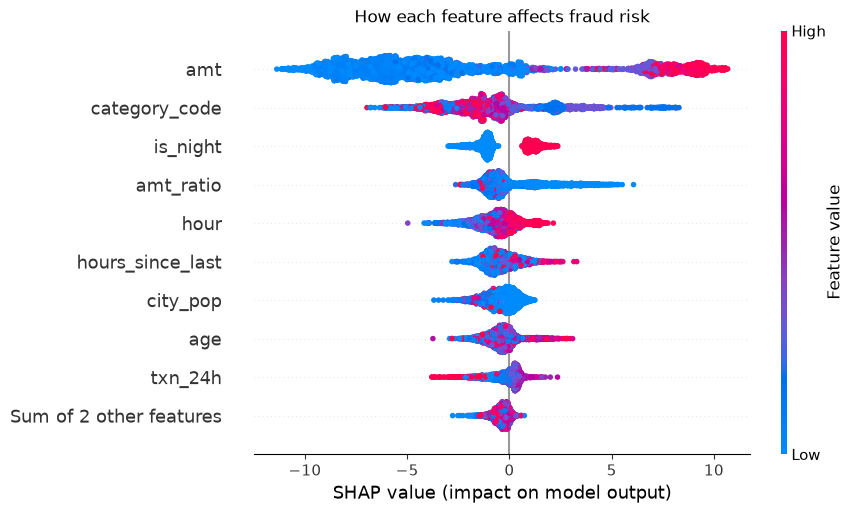

In [4]:
shap.plots.beeswarm(sv, show=False)
plt.title("How each feature affects fraud risk")
plt.savefig("../images/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

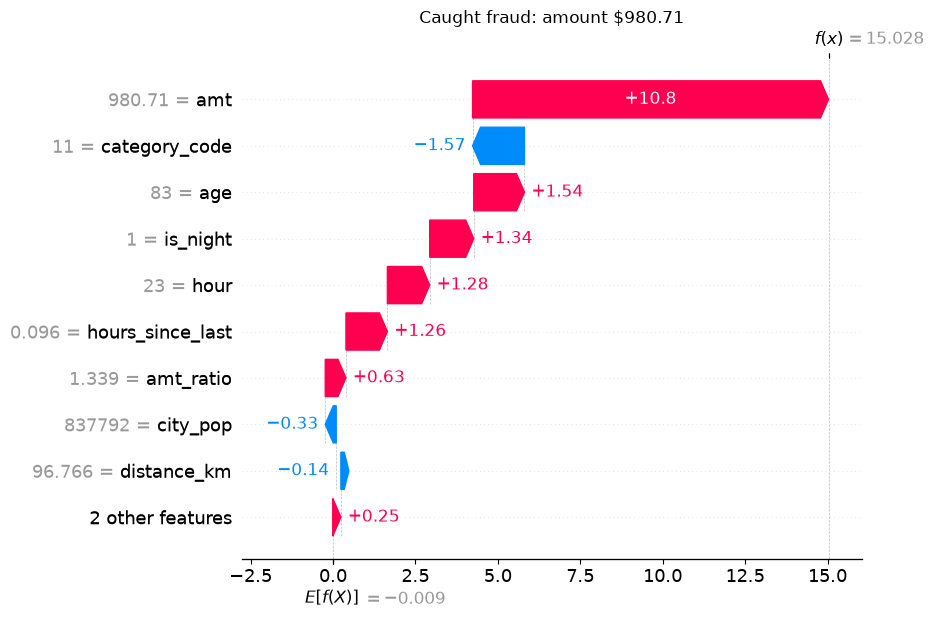

In [5]:
idx = pred[pred["is_fraud"] == 1]["proba"].idxmax()
one = explainer(X_test.loc[[idx]])

shap.plots.waterfall(one[0], show=False)
plt.title(f"Caught fraud: amount ${test.loc[idx, 'amt']:,.2f}")
plt.savefig("../images/shap_caught_fraud.png", dpi=150, bbox_inches="tight")
plt.show()


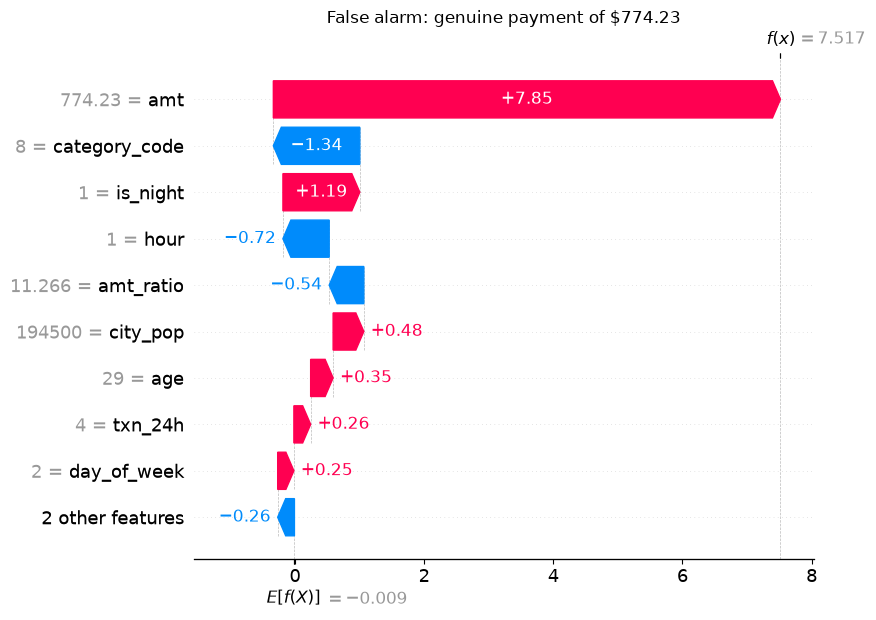

In [6]:
fa = pred[(pred["is_fraud"] == 0) & (pred["proba"] >= threshold)]
idx_fa = fa["proba"].idxmax()
one_fa = explainer(X_test.loc[[idx_fa]])

shap.plots.waterfall(one_fa[0], show=False)
plt.title(f"False alarm: genuine payment of ${test.loc[idx_fa, 'amt']:,.2f}")
plt.savefig("../images/shap_false_alarm.png", dpi=150, bbox_inches="tight")
plt.show()

In [1]:
   %pip install streamlit
   import xgboost, sklearn, shap, streamlit
   for m in [xgboost, sklearn, shap, streamlit]:
       print(m.__name__, m.__version__)

Note: you may need to restart the kernel to use updated packages.
xgboost 3.4.1
sklearn 1.9.0
shap 0.52.0
streamlit 1.58.0
